# Exploración de la reconstrucción de los autoencoders

Plantilla del change `ae-reconstruccion` (tarea 8.4). **Nivel 1: sin TensorFlow.**
Lee `reconstruction.parquet`, `diagnostics.parquet` y las métricas del run de AE
desde el estado de MLflow (`analysis/load.py`, sin duplicar la carga).

Diagnósticos de aplanamiento: razón de varianza, pendiente real vs reconstruido,
error por nivel de concentración, y comparación contra `ref-mean` y `ref-pca-d*`.

Gráficos con matplotlib (no Plotly: en el Space las figuras interactivas tardan demasiado).

In [1]:
import sys, pathlib
# Raíz de importación del pipeline: el notebook vive en notebooks/ (o en la raíz del repo).
_here = pathlib.Path.cwd()
PIPELINE = next(p for p in (_here / "pipeline", _here.parent / "pipeline") if p.exists())
sys.path.insert(0, str(PIPELINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis import load
from features.build import load_validated
from ae import data as aed
from ae import dmd as dmdm
from ae import metrics as aem

BUCKET_DATA = "sinca-data"
# Credenciales: el rol del Space (sinca-dev-role) las provee; no escribir claves aquí.

## 1. Estado de MLflow y runs de autoencoder

In [2]:
state = load.ensure_state()  # S3 real (sinca-mlflow/_mlflow); o load.ensure_state(data_dir=<fixture>)
runs = load.list_runs(state)
ae_runs = load.ae_runs(runs)
refs = [r for r in runs if load.is_reference_run(r)]
print("AE:", [r["run_name"] for r in ae_runs])
print("Referencias:", [r["run_name"] for r in refs])

AE: ['sinca-zona-ae_conv1d-v0', 'sinca-zona-ae_conv1d-v0', 'sinca-zona-ae_conv1d-v0', 'sinca-zona-ae_conv1d-v0', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v1', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_conv1d-v2', 'sinca-zona-ae_gru-v0', 'sinca-zona-ae_gru-v0', 'sinca-zona-ae_gru-v0', 'sinca-zona-ae_gru-v1', 'sinca-zona-ae_gru-v1', 'sinca-zona-ae_gru-v1', 'sinca-zona-ae_linear_decoder-v0', 'sinca-zona-ae_linear_decoder-v0', 'sinca-zona-ae_linear_decoder-v0', 'sinca-zona-ae_linear_decoder-v0', 'sinca-zona-ae_linear_decoder-v1', 'sinca-zona-ae_linear_decoder-v1', 'sinca-zona-ae_linear_decoder-v1', 'sinca-zona-ae_mlp-v0', 'sinca-zona-ae_mlp-v0', 'sinca-zona-ae_mlp-v0', 'sinca-zona-ae_mlp-v0', 'sinca-zona-ae_mlp-v1', 'sinca-zona-ae_mlp-v1', 'si

## 2. Elegir un run y cargar sus artefactos

In [3]:
RUN_NAME = ae_runs[-1]["run_name"]  # cambiar a mano para comparar otro run
run = next(r for r in ae_runs if r["run_name"] == RUN_NAME)
arts = load.load_artifacts(state, run["run_id"])
recon, diag = arts["reconstruction.parquet"], arts["diagnostics.parquet"]
print("compuerta:", run["metrics"].get("gate_pass"), "| supera PCA:", run["metrics"].get("gate_beats_pca"))

compuerta: 0.0 | supera PCA: 0.0


## 3. Real vs reconstruido con zoom a un episodio

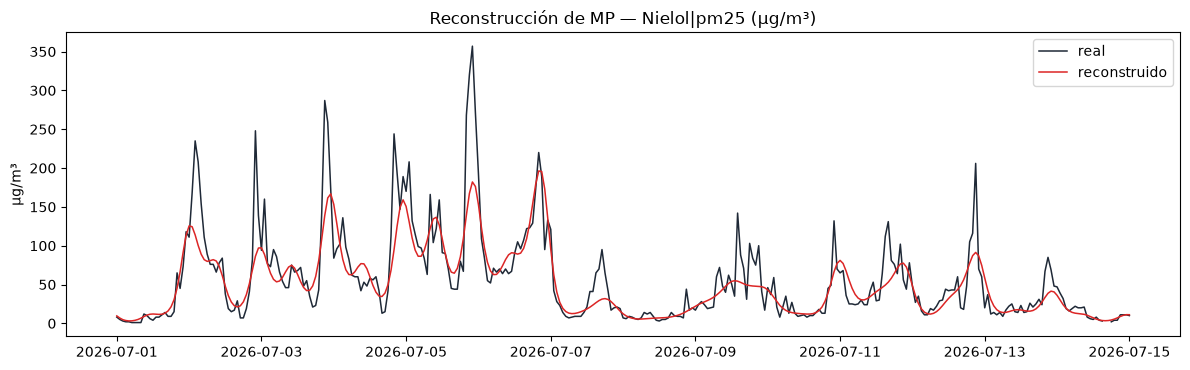

In [4]:
serie = "Nielol|pm25"
frame = recon[recon["serie"] == serie].sort_values("timestamp")
ts = frame["timestamp"]
frame = frame[(ts >= pd.Timestamp("2026-07-01", tz=ts.dt.tz)) & (ts <= pd.Timestamp("2026-07-15", tz=ts.dt.tz))]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(frame["timestamp"], frame["y_true"], lw=1.1, color="#1f2937", label="real")
ax.plot(frame["timestamp"], frame["y_recon"], lw=1.1, color="#dc2626", label="reconstruido")
ax.set_title(f"Reconstrucción de MP — {serie} (µg/m³)")
ax.set_ylabel("µg/m³")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Aplanamiento y error por nivel de concentración

metric,bias,bias_50_100,bias_gt100,bias_lt50,max_capture,n_50_100,n_gt100,n_lt50,p95_ratio,p99_ratio,rmse,rmse_50_100,rmse_gt100,rmse_lt50,slope,spec_ratio_24_168h,spec_ratio_ge168h,spec_ratio_lt24h,var_ratio
serie,,,,,,,,,,,,,,,,,,,
las_encinas_pm10,-5.461,-8.307,-44.647,0.923,0.695,216.0,125.5,1014.0,0.819,0.807,26.408,26.049,71.165,9.440,0.683,0.597,0.797,0.278,0.789
las_encinas_pm25,-4.265,-7.907,-40.743,0.528,0.823,175.0,104.5,1066.5,0.870,0.890,24.770,29.744,70.824,9.084,0.710,0.547,0.724,0.289,0.831
nielol_pm10,-3.176,-8.060,-65.770,1.756,0.425,175.5,64.5,1107.0,0.816,0.630,22.391,22.269,83.145,9.702,0.552,0.622,0.877,0.145,0.662
nielol_pm25,-3.727,-11.907,-65.366,0.535,0.467,134.5,53.0,1161.5,0.811,0.680,20.940,26.467,81.981,9.144,0.571,0.519,0.802,0.146,0.680
padre_las_casas_ii_pm10,-0.680,-1.215,-28.627,3.663,0.714,198.5,141.0,1005.0,0.929,0.890,28.696,28.202,72.376,11.892,0.736,0.847,0.908,0.437,0.885
padre_las_casas_ii_pm25,-1.252,-4.713,-26.933,2.269,0.804,163.0,118.5,1063.0,0.928,0.936,25.994,30.470,70.125,10.295,0.764,0.881,0.930,0.510,0.919


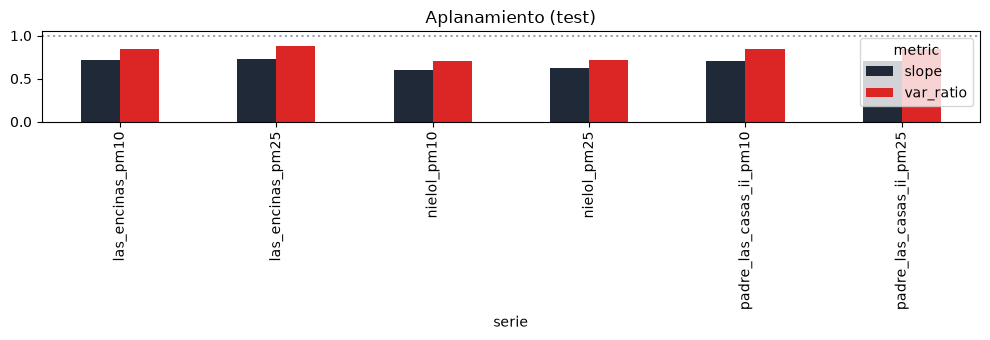

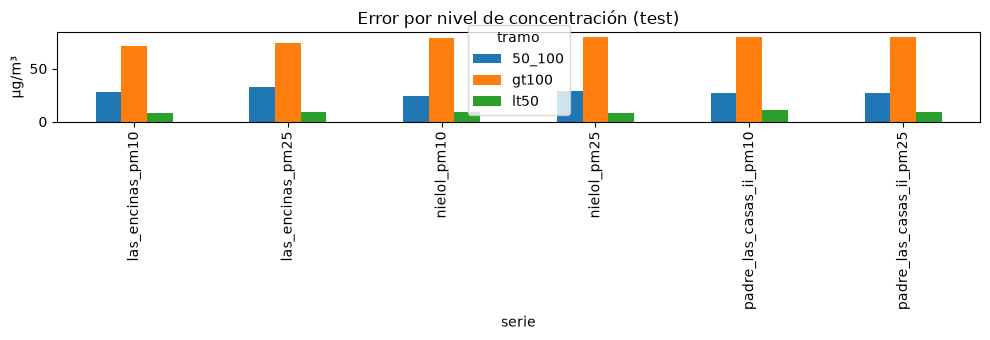

In [5]:
display(diag.pivot_table(index="serie", columns="metric", values="value").round(3))
test = diag[diag["split"] == "test"]

# Aplanamiento: razón de varianza y pendiente por serie (1 = ideal)
flat = test[test["metric"].isin(["var_ratio", "slope"])].pivot_table(index="serie", columns="metric", values="value", aggfunc="first")
ax = flat.plot.bar(figsize=(10, 3.5), color={"var_ratio": "#dc2626", "slope": "#1f2937"}, title="Aplanamiento (test)")
ax.axhline(1.0, ls=":", color="#9ca3af")
plt.tight_layout()
plt.show()

# Error por nivel de concentración (RMSE por tramo, µg/m³)
rows = []
for serie, group in test.groupby("serie"):
    vals = dict(zip(group["metric"], group["value"]))
    for b in ("lt50", "50_100", "gt100"):
        if f"rmse_{b}" in vals:
            rows.append({"serie": serie, "tramo": b, "rmse": vals[f"rmse_{b}"]})
err = pd.DataFrame(rows).pivot(index="serie", columns="tramo", values="rmse")
err.plot.bar(figsize=(10, 3.5), title="Error por nivel de concentración (test)", ylabel="µg/m³")
plt.tight_layout()
plt.show()

## 5. Contra las referencias y ablación de z_aux

In [6]:
rows = [{"run": run["run_name"], **load.ae_metric(run, "recon_rmse_mean_")}]
rows += [{"run": r["run_name"], "test": r["metrics"].get("recon_rmse_mean_test"), "valid": r["metrics"].get("recon_rmse_mean_valid")} for r in refs]
display(pd.DataFrame(rows))
print("Δ RMSE al anular z_aux (test):", run["metrics"].get("ablation_zaux_delta_rmse_test"))

,run,test,valid
0,sinca-zona-ae_mlp-v1,23.520619,26.211989
1,ref-mean,44.846954,55.086469
2,ref-mean,45.557723,55.086469
3,ref-mean,44.846954,55.086469
4,ref-mean,44.846954,55.086469
5,ref-mean,44.846954,55.086469
6,ref-mean,45.557723,55.086469
7,ref-pca-d16,17.091225,19.270375
8,ref-pca-d16,22.824800,26.115309
9,ref-pca-d16,17.091225,19.270375


Δ RMSE al anular z_aux (test): 4.483072379381213
